# MonReader — 04 Generalization, Uncertainty, and Stress Testing

> **Submission status:** reproducible historical robustness notebook.  
> **Scientific authority:** historical pre-V2 evidence; current V2 remains authoritative.

## Purpose

Evaluate the already-frozen historical ResNet18 under O/S/T/ST, quantify uncertainty at both frame and source-video levels, and characterize failure modes without post-hoc tuning.

## Notebook flow

**Frozen held-out performance → bootstrap uncertainty → failure diagnostics → stress figures → interpretation**

Source-video uncertainty is primary because frames from the same source video are correlated.

---

In [ ]:
from pathlib import Path
import sys

# Portable repository discovery: no machine-specific path assumptions.
HERE = Path.cwd().resolve()
REPO_ROOT = next(
    (p for p in [HERE, *HERE.parents] if (p / "submission" / "results").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from inside a clone of the MonReader repository "
        "or set MONREADER_REPO_ROOT."
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from submission.src.repro import (
    load_local_env,
    load_snapshot,
    display_snapshot,
    display_figure,
    figures_dir,
    data_root,
)

load_local_env()

print(f"Repository root: {REPO_ROOT}")
print(f"Committed results: {REPO_ROOT / 'submission' / 'results'}")
print(f"Committed figures: {figures_dir()}")
print(
    "Optional local data root:",
    data_root() or "not configured — report mode remains fully reviewable",
)


## Frozen ResNet18 held-out performance

| regime   |   n_samples |   n_source_videos |   notflip_f1 |   flip_f1 |   macro_f1 |   accuracy |   balanced_accuracy |   roc_auc_flip |   pr_auc_flip |    mcc |
|:---------|------------:|------------------:|-------------:|----------:|-----------:|-----------:|--------------------:|---------------:|--------------:|-------:|
| O        |         597 |               115 |       0.9951 |    0.9948 |     0.995  |     0.995  |              0.9948 |         1      |        1      | 0.99   |
| S        |         610 |                24 |       0.9635 |    0.9533 |     0.9584 |     0.959  |              0.9582 |         0.9896 |        0.9896 | 0.9168 |
| T        |         301 |               117 |       0.9194 |    0.8989 |     0.9091 |     0.9103 |              0.9082 |         0.987  |        0.9896 | 0.8334 |
| ST       |         121 |                24 |       0.9067 |    0.8478 |     0.8772 |     0.8843 |              0.8679 |         0.9197 |        0.9237 | 0.7812 |

> Snapshot source: `submission/results/resnet18_heldout_metrics.csv`


## Frame versus source-video bootstrap uncertainty

| regime   |   point_estimate |   frame_ci_lower |   frame_ci_upper |   frame_ci_width |   source_video_ci_lower |   source_video_ci_upper |   source_video_ci_width |
|:---------|-----------------:|-----------------:|-----------------:|-----------------:|------------------------:|------------------------:|------------------------:|
| O        |           0.995  |           0.9883 |           1      |           0.0117 |                  0.9862 |                  1      |                  0.0138 |
| S        |           0.9584 |           0.9421 |           0.9734 |           0.0313 |                  0.9084 |                  0.9938 |                  0.0854 |
| T        |           0.9091 |           0.8749 |           0.9398 |           0.0649 |                  0.8619 |                  0.9467 |                  0.0848 |
| ST       |           0.8772 |           0.8116 |           0.9326 |           0.121  |                  0.7469 |                  0.972  |                  0.225  |

> Snapshot source: `submission/results/bootstrap_ci_comparison.csv`


Source-video bootstrap intervals are primary because frames from one video are correlated. The ST interval is much wider than O, reflecting the smaller number of independent test sources.

## Failure summary

| regime   |   n_samples |   n_correct |   n_errors |   error_rate |   tn |   fp |   fn |   tp |
|:---------|------------:|------------:|-----------:|-------------:|-----:|-----:|-----:|-----:|
| O        |         597 |         594 |          3 |       0.005  |  307 |    0 |    3 |  287 |
| S        |         610 |         585 |         25 |       0.041  |  330 |   12 |   13 |  255 |
| T        |         301 |         274 |         27 |       0.0897 |  154 |    0 |   27 |  120 |
| ST       |         121 |         107 |         14 |       0.1157 |   68 |    0 |   14 |   39 |

> Snapshot source: `submission/results/failure_summary.csv`


## Robustness and uncertainty figures

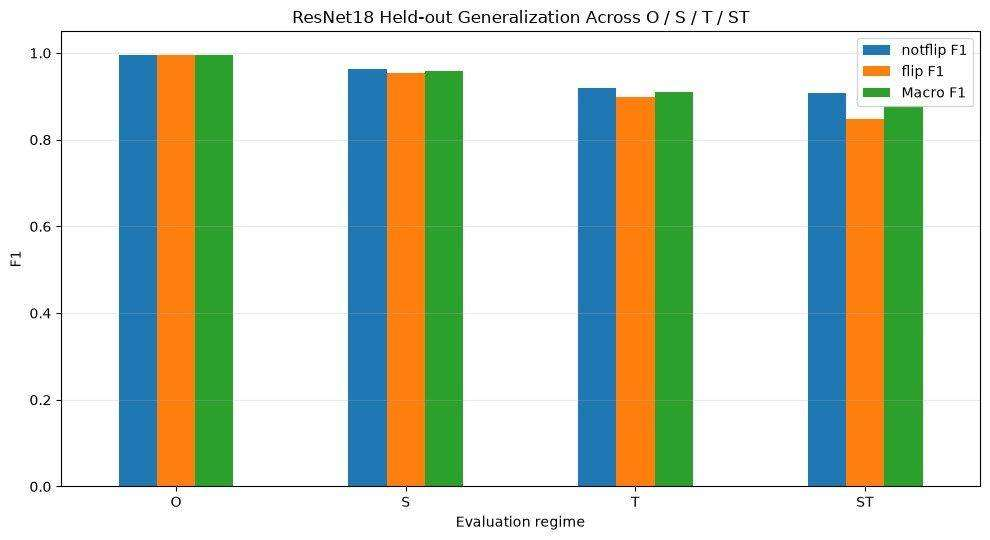

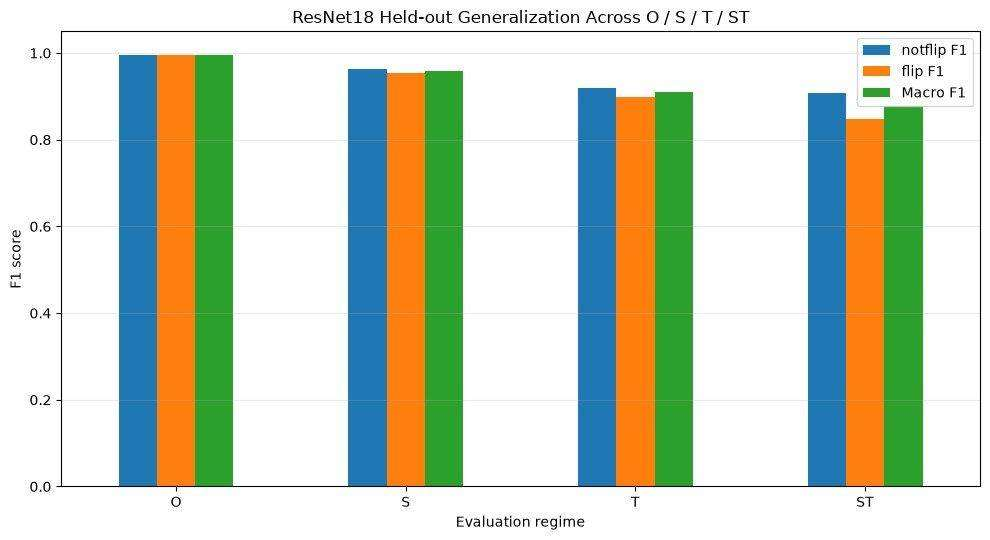

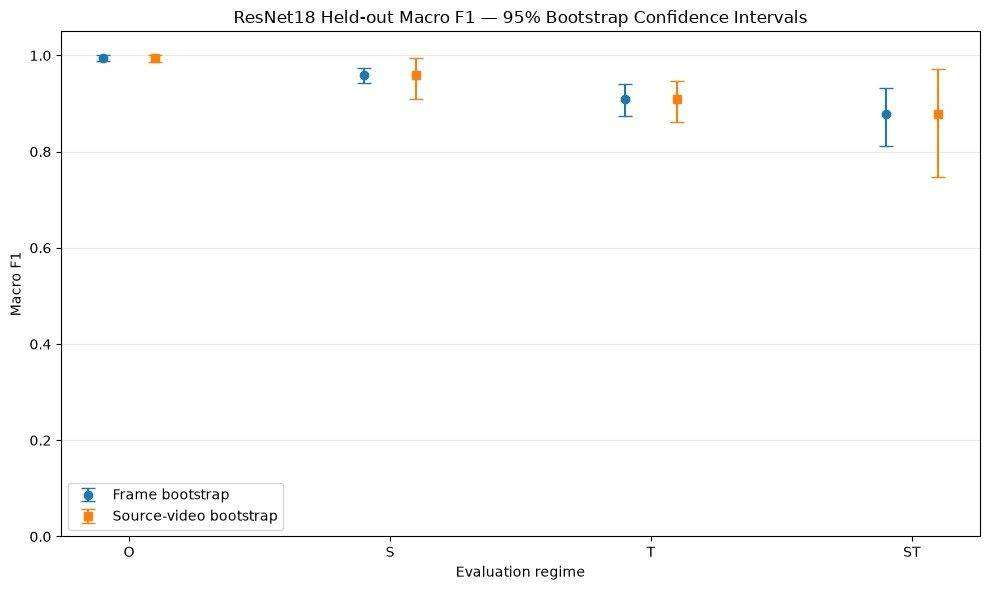

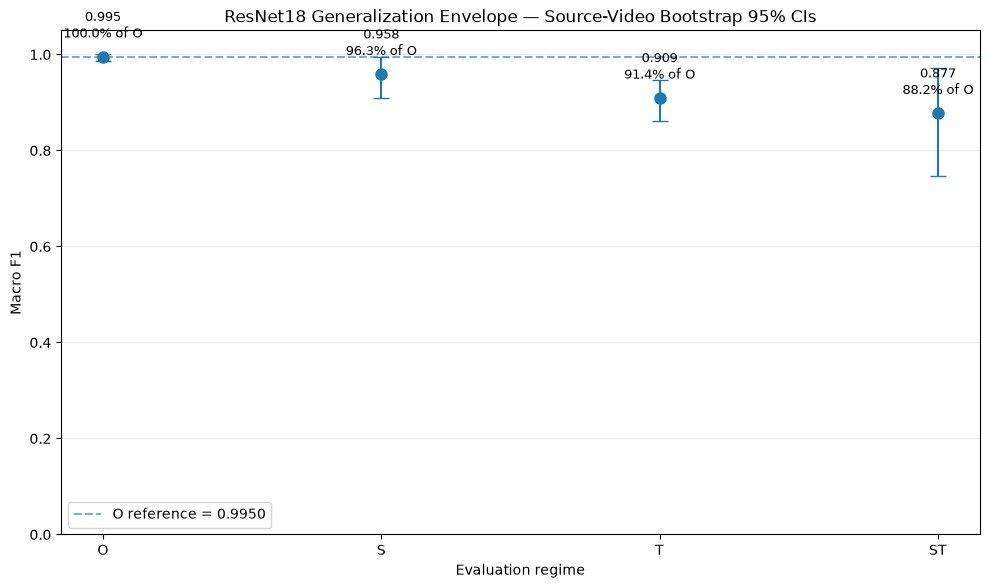

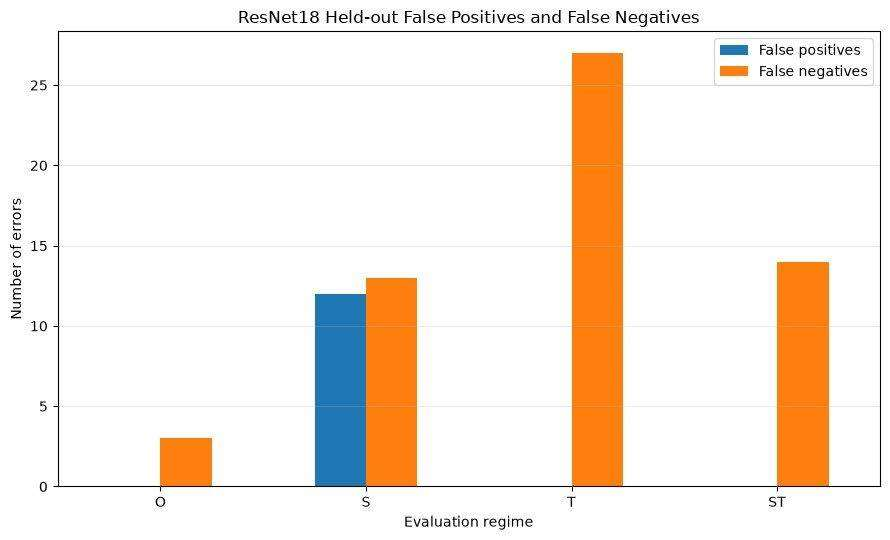

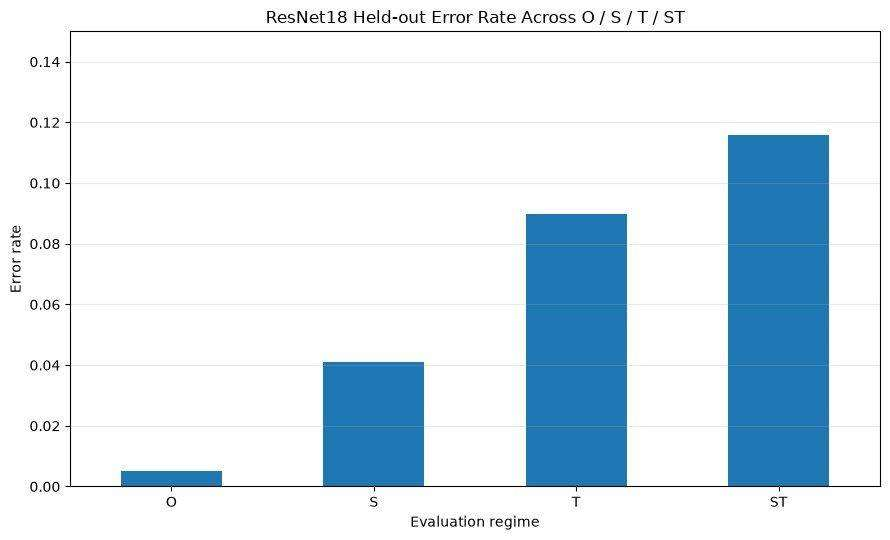

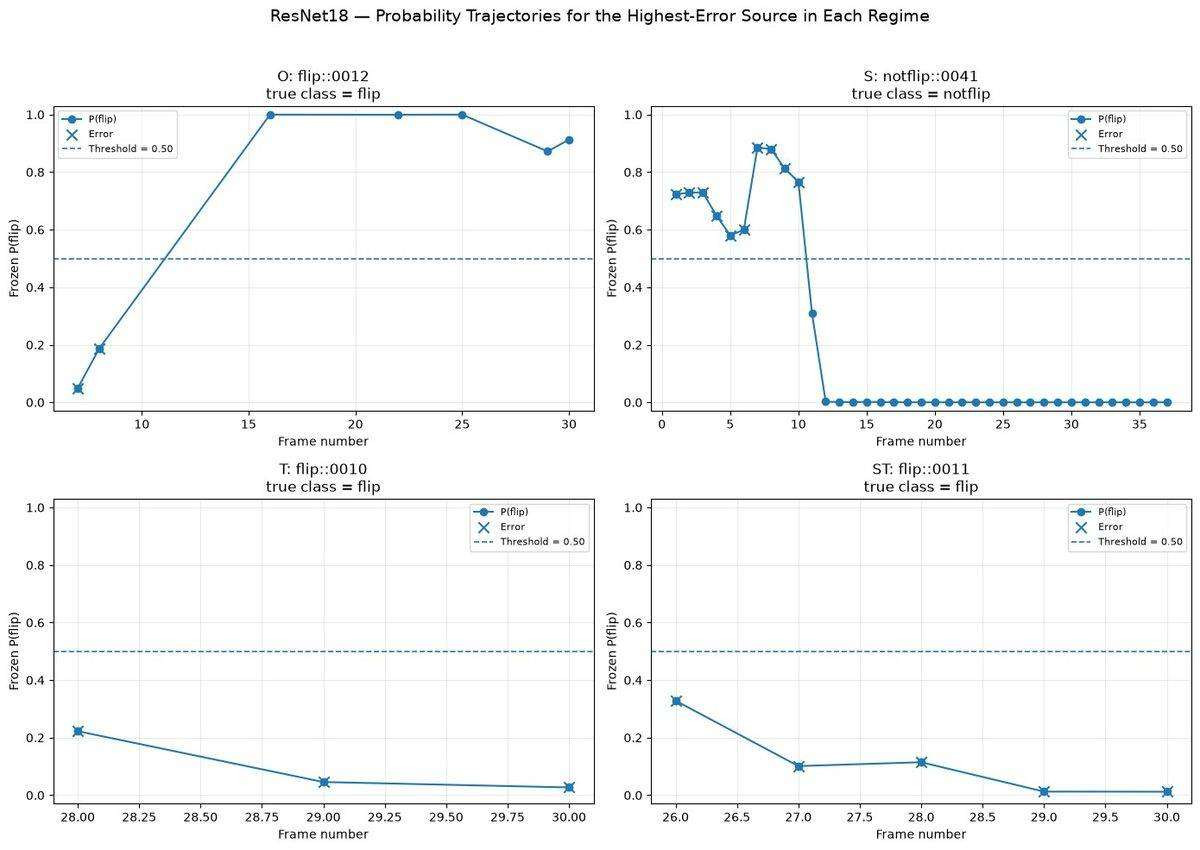

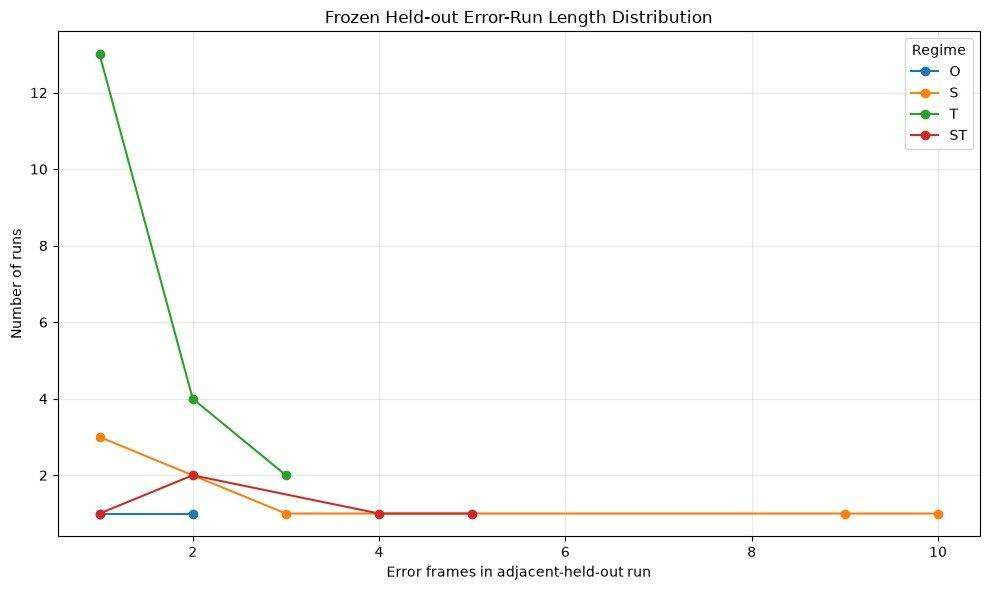

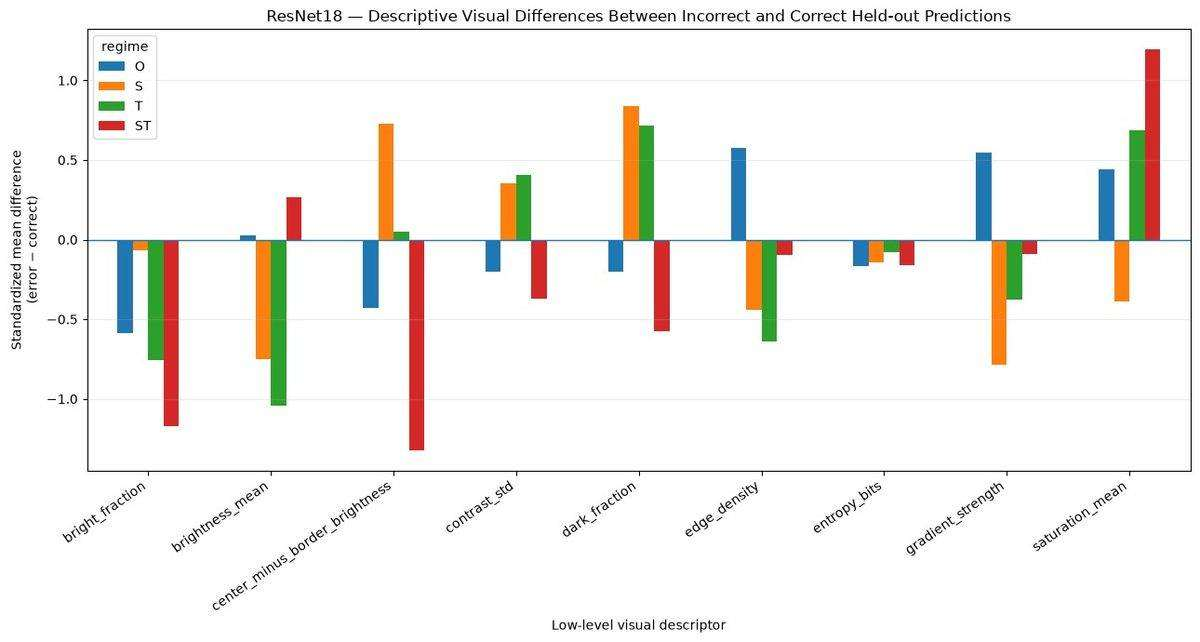

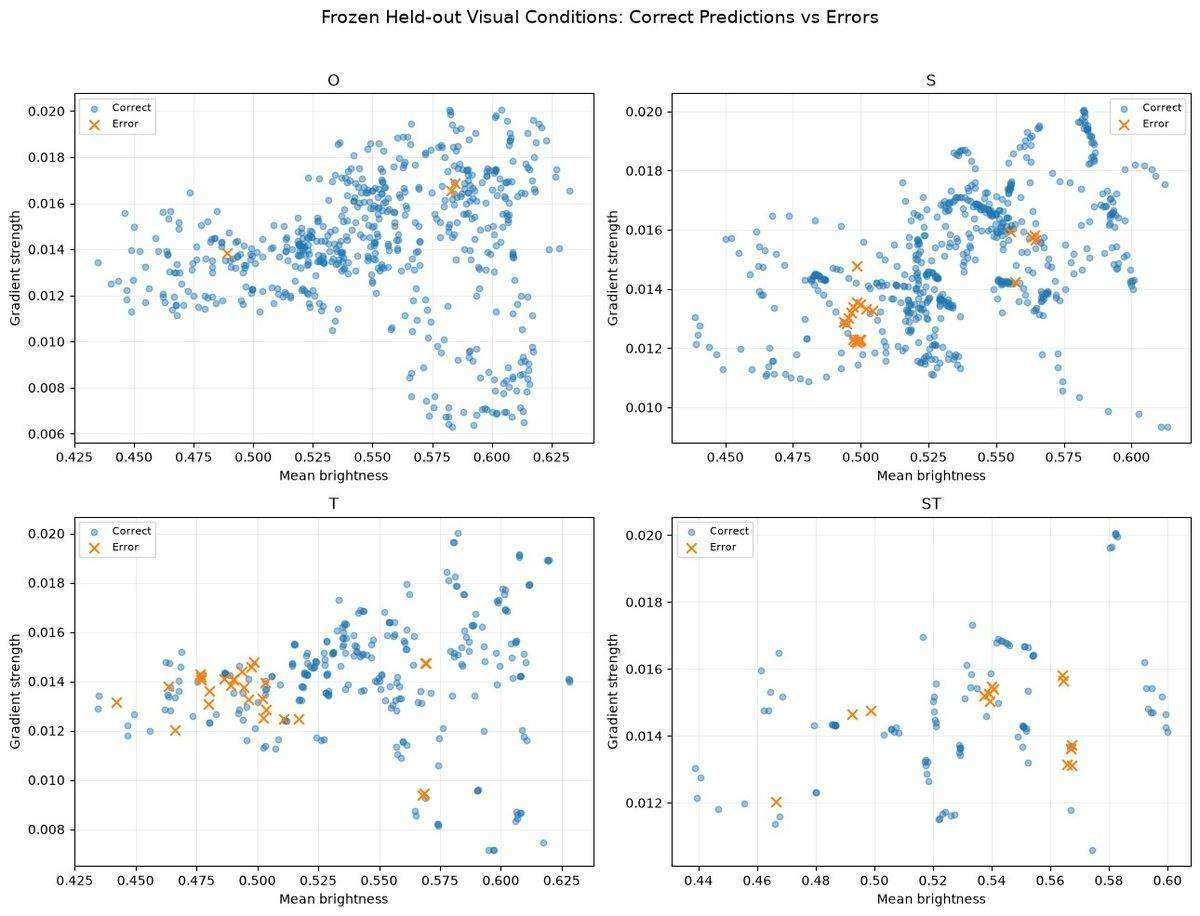

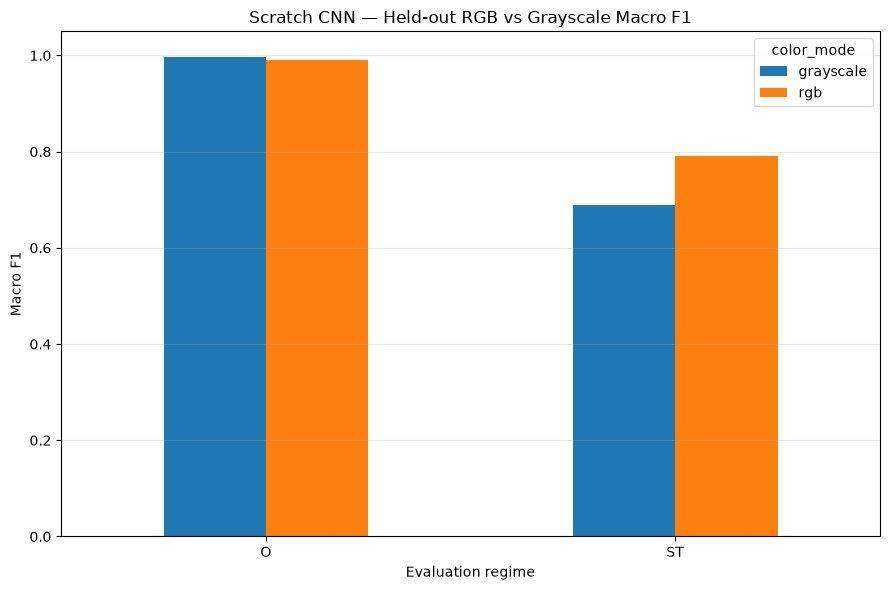

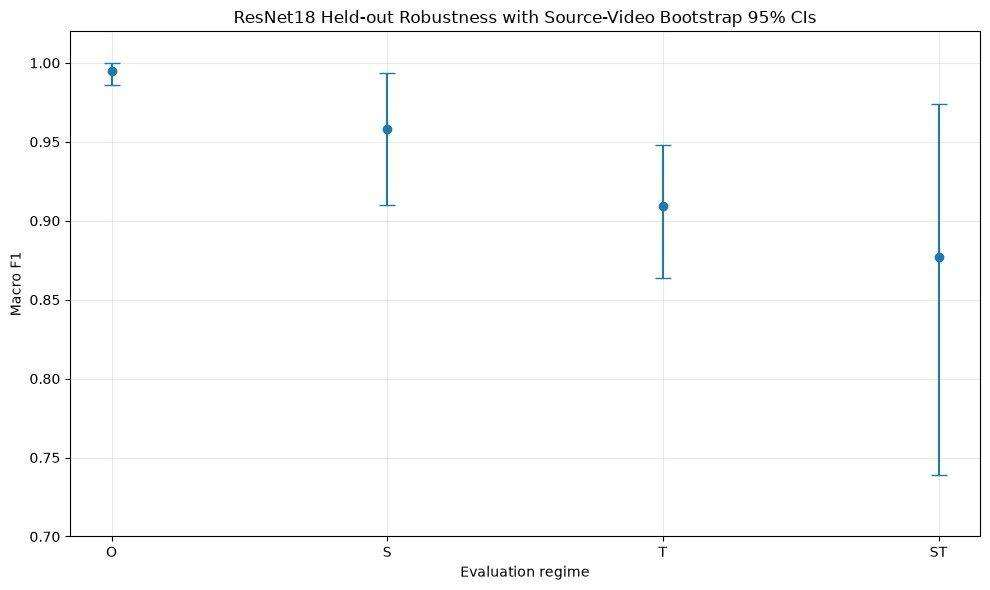


## Interpretation

The historical ResNet18 robustness envelope declines from O to S/T/ST. O is near ceiling, while ST has the lowest point performance and the widest source-video uncertainty. Failure analysis also shows that false negatives dominate and that the harder temporal regimes contain a larger share of highly confident errors.

These are descriptive robustness findings across different frozen populations—not causal estimates of a single distribution-shift mechanism.

Notebook 5 consolidates these frozen results and adds deterministic interpretability diagnostics without reopening the experiment.